<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter5/pinn_drop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Discovering the trajectory of an object via 2 hidden layer PINN.

 Starting Zero-Data PINN: Free-Falling Object 


/tmp/ipykernel_4416/3971452903.py:131: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Iteration  100 | Total Loss: 3.08070
Iteration  200 | Total Loss: 0.23885
Iteration  300 | Total Loss: 0.06835
Iteration  400 | Total Loss: 0.00985
Iteration  500 | Total Loss: 0.00632
Iteration  600 | Total Loss: 0.00432
Iteration  700 | Total Loss: 0.00348
Iteration  800 | Total Loss: 0.00269
Iteration  900 | Total Loss: 0.00247
Iteration 1000 | Total Loss: 0.00206
Iteration 1100 | Total Loss: 0.00124
Iteration 1200 | Total Loss: 0.00087
Iteration 1300 | Total Loss: 0.00068
Iteration 1400 | Total Loss: 0.00057
Iteration 1500 | Total Loss: 0.00055
Iteration 1600 | Total Loss: 0.00052
Iteration 1700 | Total Loss: 0.00045
Iteration 1800 | Total Loss: 0.00042
Iteration 1900 | Total Loss: 0.00038
Iteration 2000 | Total Loss: 0.00036
Iteration 2100 | Total Loss: 0.00031
Iteration 2200 | Total Loss: 0.00028
Iteration 2300 | Total Loss: 0.00026
Iteration 2400 | Total Loss: 0.00025
Iteration 2500 | Total Loss: 0.00024
Iteration 2600 | Total Loss: 0.00023
Iteration 2700 | Total Loss: 0.00023
I

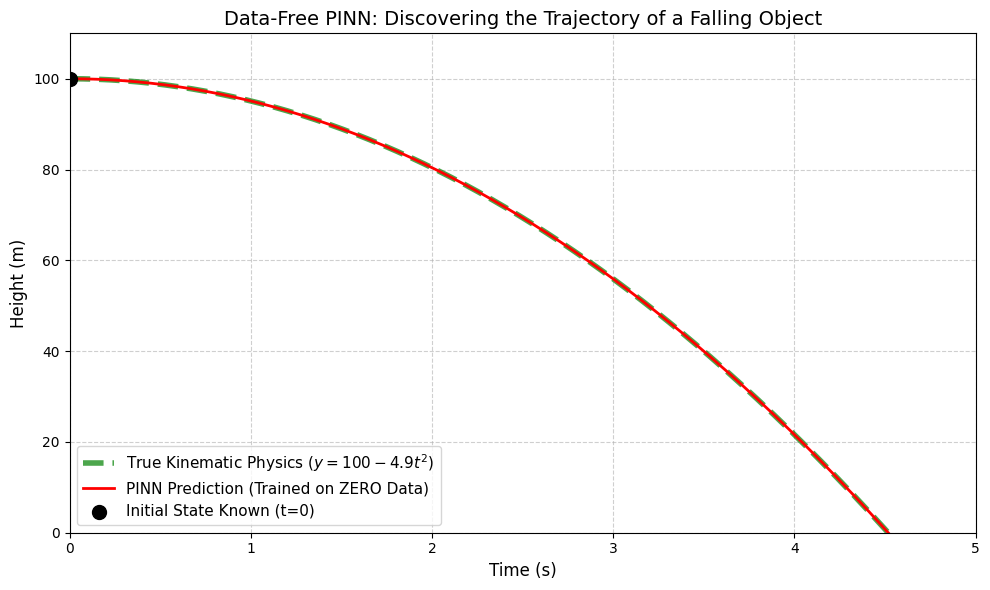

In [1]:
import jax
import jax.numpy as jnp
from jax import jit, value_and_grad, grad, vmap

# Force JAX to use 64-bit precision to prevent crashes and ensure accuracy
jax.config.update("jax_enable_x64", True)

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import time

# ==========================================
# 1. 2-Layer PINN Architecture
# ==========================================
def unpack_weights(params, H):
    """Reconstructs the weight matrices from the flat 1D array."""
    idx = 0
    W1 = params[idx : idx+H].reshape(1, H); idx += H
    b1 = params[idx : idx+H].reshape(1, H); idx += H
    W2 = params[idx : idx+H*H].reshape(H, H); idx += H*H
    b2 = params[idx : idx+H].reshape(1, H); idx += H
    W3 = params[idx : idx+H].reshape(H, 1); idx += H
    b3 = params[idx : idx+1].reshape(1, 1); idx += 1
    return W1, b1, W2, b2, W3, b3

def pack_weights(W1, b1, W2, b2, W3, b3):
    """Flattens weights into a 1D array."""
    return np.concatenate([
        W1.flatten(), b1.flatten(),
        W2.flatten(), b2.flatten(),
        W3.flatten(), b3.flatten()
    ])

def predict_y(params, t_scalar, H):
    """Feed-forward neural network predicting height (y) at time (t)."""
    W1, b1, W2, b2, W3, b3 = unpack_weights(params, H)

    # Scale time to keep the math stable [0, 5] -> [0, 1]
    t_max = 5.0
    tau = t_scalar / t_max

    a1 = jnp.tanh(jnp.dot(tau, W1) + b1)
    a2 = jnp.tanh(jnp.dot(a1, W2) + b2)

    # Notice we don't apply tanh to the final output,
    # because our height starts at 100 (way outside the [-1, 1] range of tanh!)
    y = jnp.dot(a2, W3) + b3
    return y[0, 0]

# ==========================================
# 2. Universal AutoDiff Physics Builder
# ==========================================
# Ask JAX to dynamically build the exact derivatives for velocity AND acceleration!
predict_velocity = grad(predict_y, argnums=1)
predict_acceleration = grad(predict_velocity, argnums=1)

# Vectorize the scalar functions so they can run over massive arrays of time
vmap_y = vmap(predict_y, in_axes=(None, 0, None))
vmap_velocity = vmap(predict_velocity, in_axes=(None, 0, None))
vmap_acceleration = vmap(predict_acceleration, in_axes=(None, 0, None))

def compute_loss(params, t_domain, t_ic, y_0, v_0, H):
    t_flat = t_domain.flatten()
    t_ic_flat = t_ic.flatten()

    # 1. The Physics Loss (L_ODE)
    # At every single point in time, acceleration must equal -9.8
    acceleration_pred_ode = vmap_acceleration(params, t_flat, H)
    residual = acceleration_pred_ode - (-9.8)  # -> a + 9.8 = 0
    loss_ode = jnp.mean(residual**2)

    # 2. The Initial Condition Loss (L_IC)
    # At t=0, the height must be 100, and velocity must be 0
    y_pred_ic = vmap_y(params, t_ic_flat, H)
    v_pred_ic = vmap_velocity(params, t_ic_flat, H)

    loss_ic_position = jnp.mean((y_pred_ic - y_0)**2)
    loss_ic_velocity = jnp.mean((v_pred_ic - v_0)**2)

    # Total loss is the sum of physics and initial state constraints.
    return loss_ode + loss_ic_position + loss_ic_velocity

# JIT compile the loss and gradient function for massive speedups
loss_and_grad = jit(value_and_grad(compute_loss), static_argnums=(5,))

def scipy_objective(params, t_domain, t_ic, y_0, v_0, H):
    loss, grads = loss_and_grad(params, t_domain, t_ic, y_0, v_0, H)
    return float(loss), np.array(grads)

# ==========================================
# 3. Training Setup (Data-Free Environment!)
# ==========================================
H = 32

# 400 Dense Collocation Points (The Physics Constraint track)
t_domain = jnp.linspace(0, 5, 400).reshape(-1, 1)

# The Initial State Constraint
t_ic = jnp.array([[0.0]])
y_0 = 100.0  # Dropped from 100 meters
v_0 = 0.0    # Dropped from rest

np.random.seed(42)

# Standard Glorot Initialization
# (We don't need massive frequency scaling here like we did for the pendulum
# because a parabola is a very low-frequency curve compared to sine waves!)
W1 = np.random.randn(1, H) * np.sqrt(2.0 / (1 + H))
b1 = np.zeros((1, H))
W2 = np.random.randn(H, H) * np.sqrt(2.0 / (H + H))
b2 = np.zeros((1, H))
W3 = np.random.randn(H, 1) * np.sqrt(2.0 / (H + 1))
b3 = jnp.array([[y_0]]) # Initialize bias near starting height to help it learn faster

current_weights = pack_weights(W1, b1, W2, b2, W3, b3)

progress = {'iterations': 0}

def monitor_progress(xk):
    progress['iterations'] += 1
    if progress['iterations'] % 100 == 0:
        current_loss = compute_loss(xk, t_domain, t_ic, y_0, v_0, H)
        print(f"Iteration {progress['iterations']:4d} | Total Loss: {float(current_loss):.5f}")

print("==================================================")
print(" Starting Zero-Data PINN: Free-Falling Object ")
print("==================================================")
start_time = time.time()

res = minimize(
    fun=scipy_objective,
    x0=current_weights,
    args=(t_domain, t_ic, y_0, v_0, H),
    method='L-BFGS-B',
    jac=True,
    callback=monitor_progress,
    options={'maxiter': 5000, 'maxfun': 50000, 'disp': False}
)

final_weights = res.x
elapsed = time.time() - start_time
print(f"\nTraining Complete in {elapsed:.2f}s!")
print(f"Final Loss: {res.fun:.6f}")

# ==========================================
# 4. Evaluation and Plotting
# ==========================================
t_plot = np.array(t_domain).flatten()
y_pred = np.array(vmap_y(final_weights, t_plot, H))

# Calculate the Exact Mathematical Reality using standard kinematics:
# y(t) = y_0 + v_0*t + 0.5*a*t^2
exact_solution = y_0 + (v_0 * t_plot) + (0.5 * -9.8 * (t_plot**2))

plt.figure(figsize=(10, 6))

# Plot the True Analytical Solution
plt.plot(t_plot, exact_solution, 'g--', linewidth=4, alpha=0.7, label='True Kinematic Physics ($y = 100 - 4.9t^2$)')

# Plot the PINN's Data-Free Discovery
plt.plot(t_plot, y_pred, 'r-', linewidth=2, label='PINN Prediction (Trained on ZERO Data)')

# Highlight the only piece of data the network received
plt.scatter([0], [100], color='black', s=100, zorder=5, label='Initial State Known (t=0)')

plt.title("Data-Free PINN: Discovering the Trajectory of a Falling Object", fontsize=14)
plt.xlabel("Time (s)", fontsize=12)
plt.ylabel("Height (m)", fontsize=12)
plt.legend(loc='lower left', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

# Set axes to match the physical scenario (ground is 0)
plt.ylim(0, 110)
plt.xlim(0, 5)

plt.tight_layout()
plt.show()